In [23]:
from data_processing import process_mat_file
from paths import DATA_DIR, weagets_input
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from climate_extreme import ClimateExtreme
import climate_stats as cs
import scipy.stats as stats

from BucketModel import BucketModel, BucketModelOptimizer
from BucketModel.data_processing import (
    preprocess_for_bucket_model,
    run_multiple_simulations,
)
from BucketModel.bucket_model_plotter import *

from climate_simulation import run_model_for_future_climate, plot_climate_scenarios

from uncertainty_analysis import UncertaintyAnalysis, simulate_and_aggregate_streamflows

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

import statsmodels.tsa.api as smt
import statsmodels.api as sm

from generate_future_climate import generate_future_climate

import os


import warnings
warnings.filterwarnings("ignore")

## (WEEK 1) Simulating ensembles with the WeaGETS weather generator.
### Reading in the input data and the output files from WeaGETS

<div style="background-color: #3b1d1d; padding: 12px 16px; border-radius: 6px; border-left: 4px solid #ff7f7f; margin: 10px 0; color: #ffffff; display: inline-block;">
⚠️ <strong>Important:</strong> Store the simulated data (the .mat files) in the <strong>data</strong> folder!
</div>

In [24]:
STATION = "GSTEIG"  # GSTEIG, HONDRICH or LATTERBACH
input_data_path = weagets_input(STATION)  # OBSERVATIONS dataset
WEAGETS = "O2_D2"  # chosen WeaGETS setting: Markov order 2 + Gamma (O1_D2 = order 1 + Gamma)
simulation_path = DATA_DIR / f"{STATION}_{WEAGETS}_OUT.mat"  # WeaGETS SIMULATIONS dataset (run_weagets_all.m)
future_dir = DATA_DIR / f"Future{STATION.capitalize()}_{WEAGETS}"  # future climate ensemble (delta change)

#Process the MATLAB files to a suitable format
present_data = process_mat_file(input_data_path)
simulated_data = process_mat_file(simulation_path)


In [25]:
# Inspect the OBSERVATIONS (see the number of datapoints - rows, compare it with the WeaGETS output)
present_data

,Precipitation,T_max,T_min,T_avg,Year,Month,Day
0,6.6,-6.6,-9.9,-8.25,1980,Jan,1
1,6.4,-9.8,-11.8,-10.80,1980,Jan,2
2,2.0,-10.2,-13.6,-11.90,1980,Jan,3
3,10.4,-11.7,-14.4,-13.05,1980,Jan,4
4,4.7,-7.8,-14.3,-11.05,1980,Jan,5
...,...,...,...,...,...,...,...
10945,0.1,-12.9,-17.0,-14.95,2009,Dec,27
10946,8.4,-11.9,-16.4,-14.15,2009,Dec,28
10947,2.3,-14.2,-18.8,-16.50,2009,Dec,29
10948,6.3,-8.2,-19.0,-13.60,2009,Dec,30


In [26]:
# Inspect the WeaGETS SIMULATIONS (notice that you have a "Simulation" column marking the ordinal number of the realisation)
simulated_data

,Precipitation,T_max,T_min,Year,Simulation,T_avg,Month,Day
0,0.0,4.333868,-3.105095,1980,1,0.614386,Jan,1
1,0.0,1.554963,-6.291488,1980,1,-2.368262,Jan,2
2,0.0,-1.912057,-10.155973,1980,1,-6.034015,Jan,3
3,0.0,-4.389699,-8.654014,1980,1,-6.521857,Jan,4
4,0.0,-4.219894,-7.859216,1980,1,-6.039555,Jan,5
...,...,...,...,...,...,...,...,...
547495,0.0,1.536662,-2.628541,2009,50,-0.545940,Dec,27
547496,0.0,4.469457,-2.384431,2009,50,1.042513,Dec,28
547497,0.0,7.537444,0.348343,2009,50,3.942894,Dec,29
547498,0.0,4.472686,-1.505563,2009,50,1.483561,Dec,30


## Looking at climate statistics to compare generated data to observed data
### Comparing number of wet days (Precipitation > 0.1 mm) in the generated data to the observed data

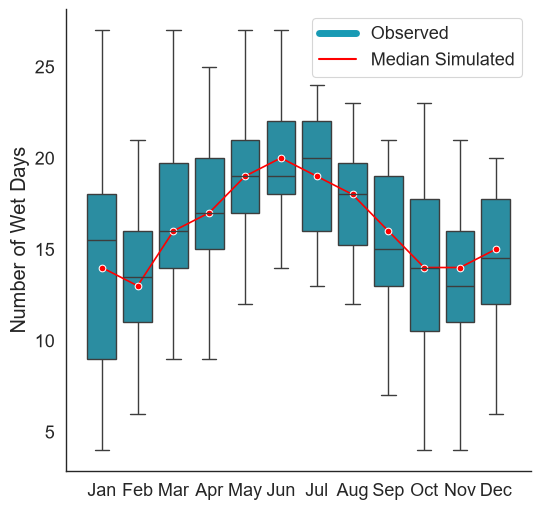

In [27]:
cs.plot_wet_days(
    present_data,
    simulated_data
) # You can add the output_destination parameter to save the plot

### Comparing the Estimated Cumulative Distribution Function (ECDF) of the two datasets for Precipitation

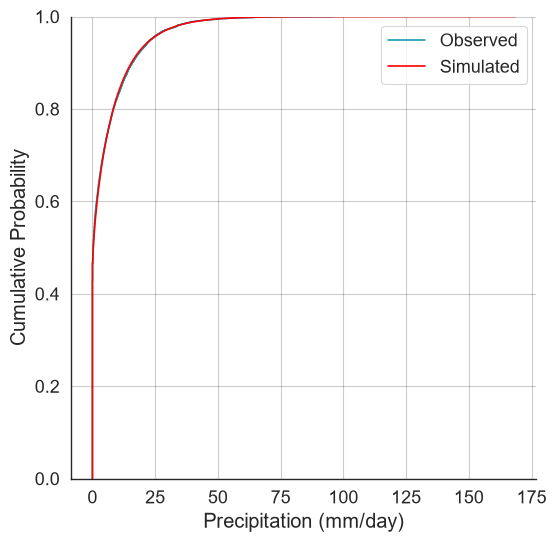

In [28]:
cs.plot_ECDF(
    observations=present_data,
    simulation=simulated_data,
    column="Precipitation",
    xlabel="Precipitation (mm/day)",
)

### Comparing mean and standard deviation of Average Temperature values

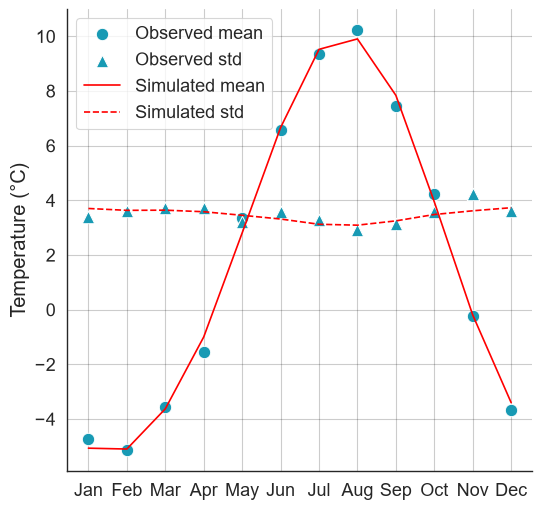

In [29]:
cs.plot_mean_and_std(observations=present_data, simulation=simulated_data)

### Compare the extreme values - Plot the distributions above a given quantile for visual inspection

In [30]:
# Create instances of ClimateExtreme Class
observed = ClimateExtreme(present_data)
simulated_extreme = ClimateExtreme(simulated_data)

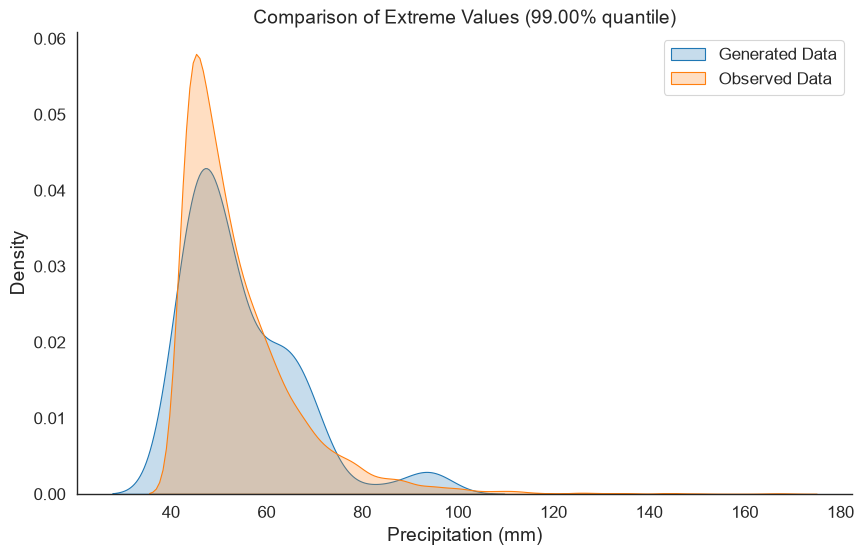

In [31]:
#These plots contain the data points 
observed.plot_extreme_comparison(column="Precipitation", other=simulated_extreme, quantile=0.99, output_destination="", units="mm")

### Perform the KS test for each WeaGETS realisation against the extremes of the observations

KS Tests Completed.


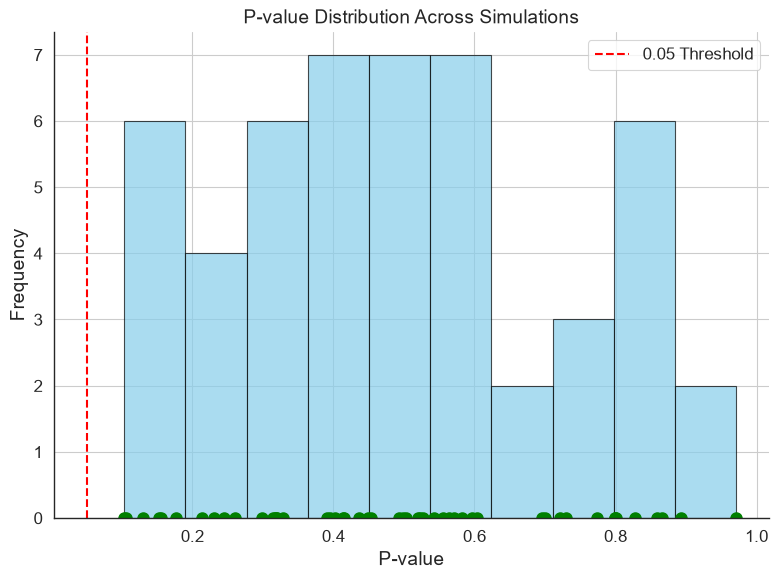

In [32]:
# Call the run_simulation_ks_tests method
ks_results = simulated_extreme.run_simulation_ks_tests(
    observed_data=observed,          # Pass the observed data instance
    column="Precipitation",     # Specify the column to compare
    quantile=0.95               # Specify the quantile for truncation
)

# Output the results
simulated_extreme.plot_ks_results(ks_results)

## Running the Bucket Model
#### Preprocessing the data to match the format required by the Bucket Model


In [33]:
processed_present_data = preprocess_for_bucket_model(present_data)
simulated_preprocessed = preprocess_for_bucket_model(simulated_data)


In [34]:
processed_present_data

,P_mix,T_max,T_min
date,,,
1980-01-01,6.6,-6.6,-9.9
1980-01-02,6.4,-9.8,-11.8
1980-01-03,2.0,-10.2,-13.6
1980-01-04,10.4,-11.7,-14.4
1980-01-05,4.7,-7.8,-14.3
...,...,...,...
2009-12-27,0.1,-12.9,-17.0
2009-12-28,8.4,-11.9,-16.4
2009-12-29,2.3,-14.2,-18.8


In [35]:
simulated_preprocessed

,P_mix,T_max,T_min,Simulation
date,,,,
1980-01-01,0.0,4.333868,-3.105095,1
1980-01-02,0.0,1.554963,-6.291488,1
1980-01-03,0.0,-1.912057,-10.155973,1
1980-01-04,0.0,-4.389699,-8.654014,1
1980-01-05,0.0,-4.219894,-7.859216,1
...,...,...,...,...
2009-12-27,0.0,1.536662,-2.628541,50
2009-12-28,0.0,4.469457,-2.384431,50
2009-12-29,0.0,7.537444,0.348343,50


### Setting up the model for the catchment. Here I use the calibrated parameters from Assignment 2

In [36]:
bucket_model = BucketModel(
    k=1.0155, S_max=10.0, fr=0.1184, rg=24.6808, snow_threshold_temp=-0.8451
)  # Parameters from Assignment 2

bucket_model.set_catchment_properties(
    lapse_rate=0.5 / 100,  # °C/m
    basin_mean_elevation=2035,  # m.a.s.l
    hru_mean_elevation=2035,  # m.a.s.l
    snowmelt_temp_threshold=0,  # °C
    latitude=46.59,  # °N
)

Catchment properties set:
  Lapse rate: 0.005 °C/m
  Basin mean elevation: 2035 m.a.s.l.
  HRU mean elevation: 2035 m.a.s.l.
  Snowmelt temperature threshold: 0 °C
  Latitude: 46.59°


### Running the model for the present data and visualising the results

In [37]:
present_results = bucket_model.run(data=processed_present_data)

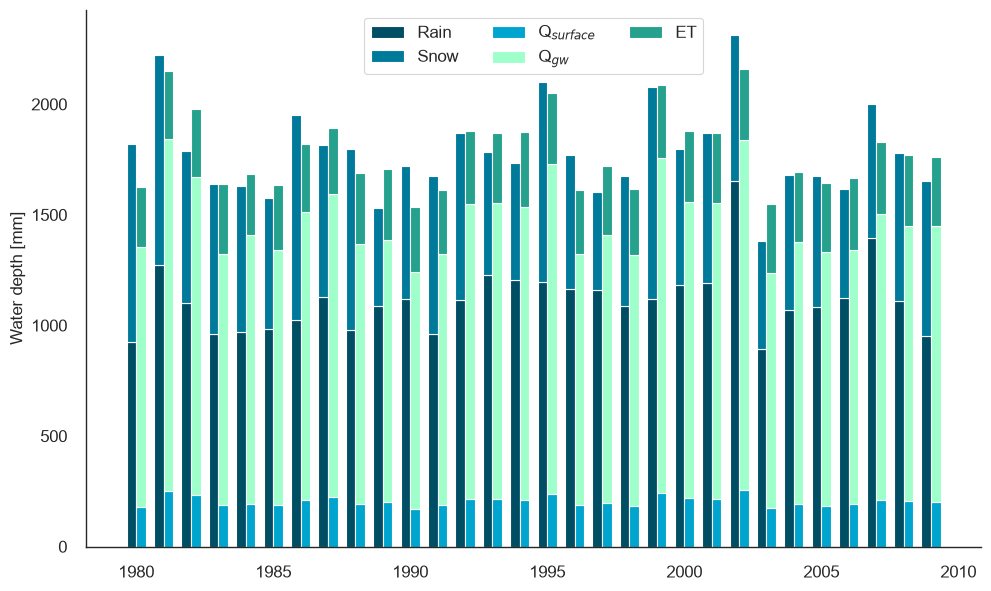

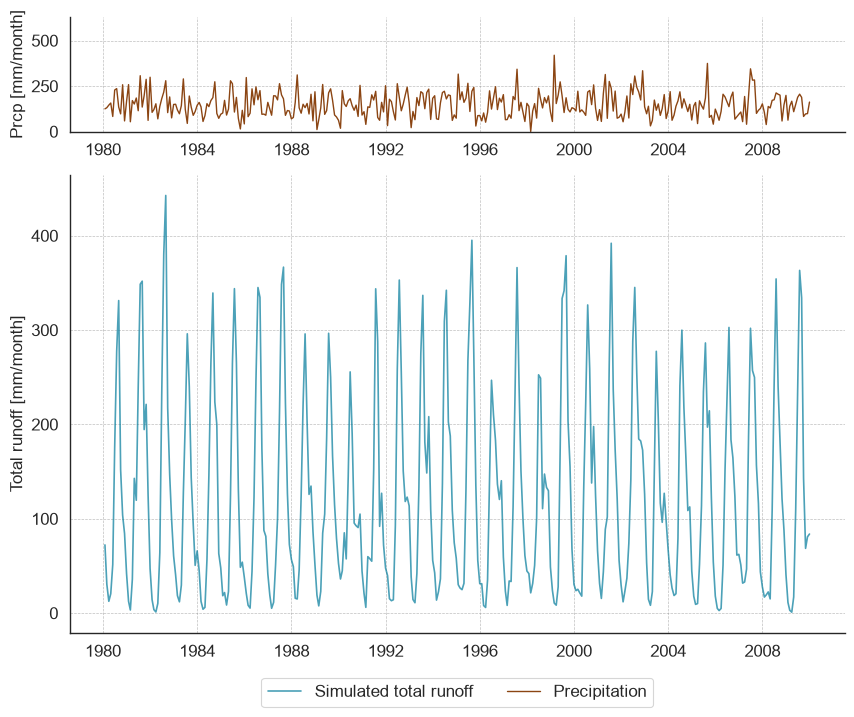

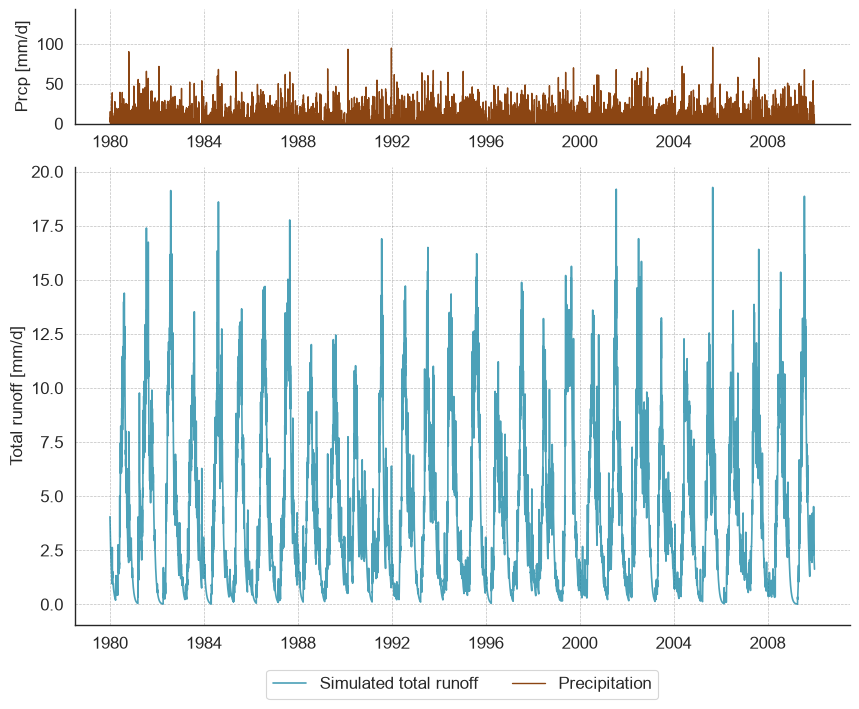

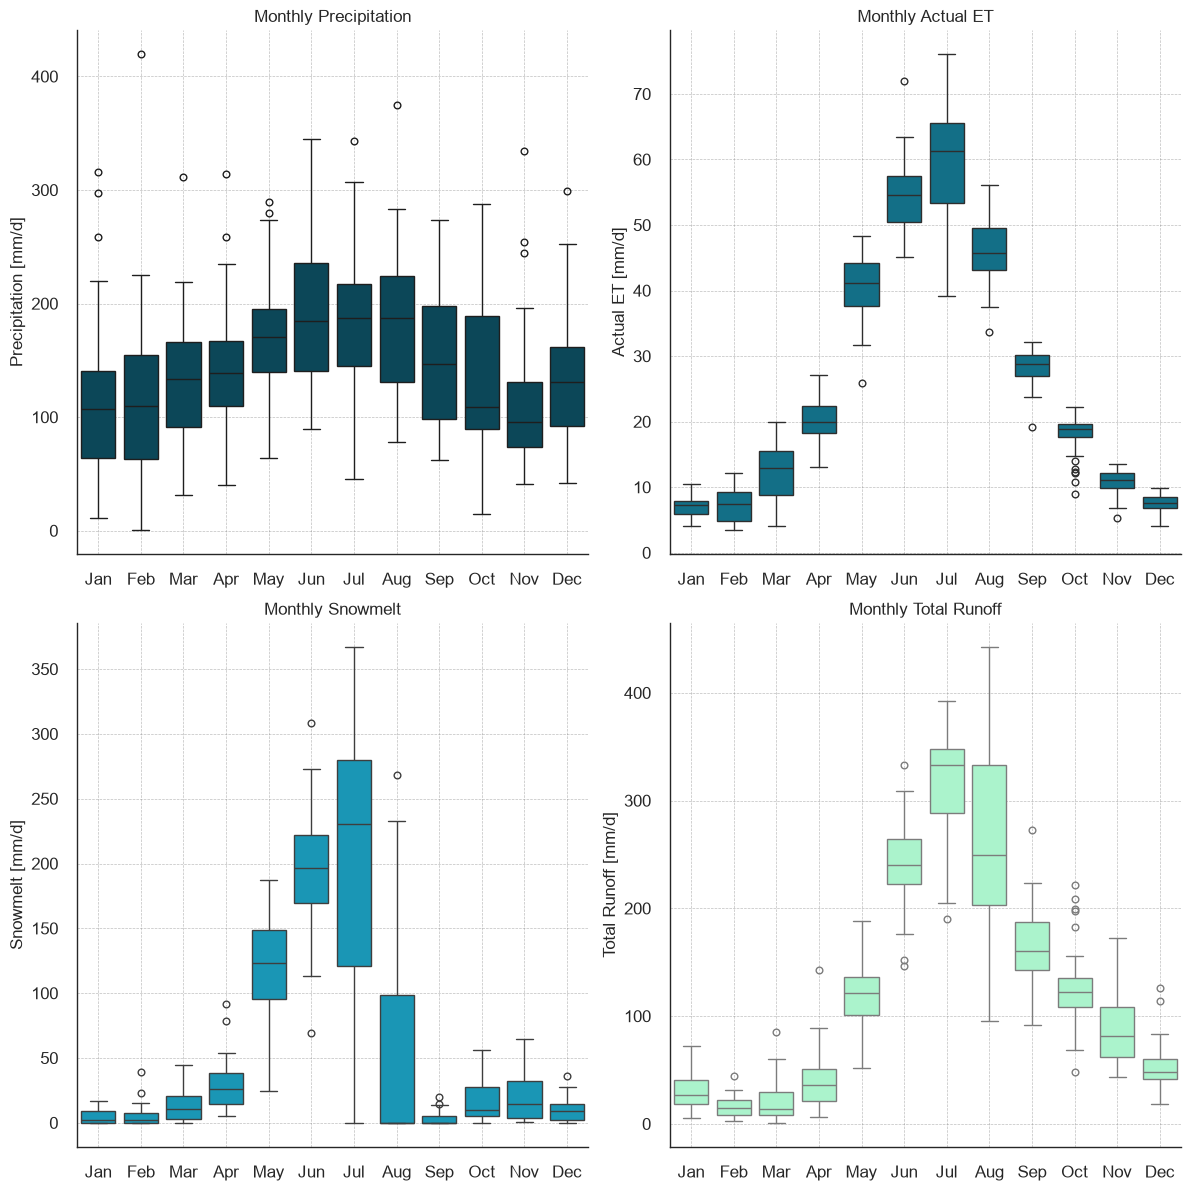

In [38]:
plot_water_balance(results=present_results, start_year="1980", end_year="2010")

plot_timeseries(
    results=present_results,
    start_year="1980",
    end_year="2010",
    monthly=True,
    plot_precipitation=True,
)
plot_timeseries(
    results=present_results,
    start_year="1980",
    end_year="2010",
    monthly=False,
    plot_precipitation=True,
)
plot_monthly_boxplot(results=present_results)

### Run the model for each Simulation individually. Here _Simulation_ refers to the number of 30 years ensembles generated with WeaGETS.

In [39]:
multiple_results = run_multiple_simulations(
    preprocessed_simulated_data=simulated_preprocessed,
    bucket_model=bucket_model,
    n_simulations=50,
)

In [40]:
multiple_results

,ET,Q_s,Q_gw,Snow_accum,S,S_gw,Snow_melt,Rain,Snow,Precip,Simulation,PET,Total_Runoff,Ice_melt,S_ice
1980-01-01,0.348296,0.000000,4.051733,0.000000,9.651704,95.948267,0.000000,0.0,0.0,0.0,1,0.348296,4.051733,0.0,0.0
1980-01-02,0.274034,0.000000,3.887567,0.000000,9.377669,92.060700,0.000000,0.0,0.0,0.0,1,0.283923,3.887567,0.0,0.0
1980-01-03,0.205459,0.000000,3.730053,0.000000,9.172210,88.330647,0.000000,0.0,0.0,0.0,1,0.219094,3.730053,0.0,0.0
1980-01-04,0.194693,0.000000,3.578922,0.000000,8.977517,84.751725,0.000000,0.0,0.0,0.0,1,0.212264,3.578922,0.0,0.0
1980-01-05,0.198231,0.000000,3.433913,0.000000,8.779286,81.317812,0.000000,0.0,0.0,0.0,1,0.220808,3.433913,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2009-12-27,0.317458,0.000000,2.047638,105.000756,9.682542,48.489708,0.000000,0.0,0.0,0.0,50,0.317458,2.047638,0.0,0.0
2009-12-28,0.343623,0.125347,1.964673,103.942085,10.000000,46.797280,1.058672,0.0,0.0,0.0,50,0.354889,2.090020,0.0,0.0
2009-12-29,0.432776,0.474075,1.896101,99.938076,10.000000,47.998337,4.004008,0.0,0.0,0.0,50,0.432776,2.370175,0.0,0.0
2009-12-30,0.367483,0.178376,1.944764,98.431520,10.000000,47.014270,1.506557,0.0,0.0,0.0,50,0.367483,2.123141,0.0,0.0


### Grouping the results by month and computing the 95% confidence interval

,year,ET,Q_s,Q_gw,Snow_accum,S,S_gw,Snow_melt,Rain,Snow,Precip,PET,Total_Runoff,Ice_melt,S_ice,total_runoff
month,,,,,,,,,,,,,,,,
1,1994.5,6.659524,2.423197,30.824004,5949.445183,244.716216,744.502635,7.919044,14.659975,102.637920,117.297895,8.233267,33.247201,0.0,0.0,33.247201
2,1994.5,6.938295,2.041883,16.865662,8129.390410,195.984538,411.113719,6.729873,13.368290,104.140778,117.509068,9.617347,18.907546,0.0,0.0,18.907546
3,1994.5,11.592826,3.955165,16.999145,11915.990056,216.180119,424.829996,13.949358,24.635530,106.304425,130.939955,15.970864,20.954310,0.0,0.0,20.954310
4,1994.5,20.791859,9.879642,34.020525,14019.103196,247.980888,862.990391,35.565657,53.942258,92.359694,146.301952,24.371534,43.900167,0.0,0.0,43.900167
5,1994.5,38.646152,26.578012,90.174649,14340.053672,296.830467,2297.206475,105.097093,122.793184,40.500364,163.293548,39.955487,116.752660,0.0,0.0,116.752660
6,1994.5,54.398897,45.124700,195.878120,9945.764635,297.424930,4920.983510,197.794410,184.095323,9.526712,193.622035,54.813223,241.002820,0.0,0.0,241.002820
7,1994.5,60.133832,45.212797,269.711084,3819.426240,287.187781,6668.182611,190.887837,194.359929,1.157814,195.517744,64.819979,314.923881,0.0,0.0,314.923881
8,1994.5,45.601605,25.028896,218.757187,436.687521,254.404017,5328.807150,41.093815,177.834632,0.721667,178.556299,55.924647,243.786083,0.0,0.0,243.786083
9,1994.5,30.065484,16.943658,145.693835,27.080559,244.145773,3552.332220,4.175478,144.669592,3.128049,147.797642,37.084682,162.637493,0.0,0.0,162.637493


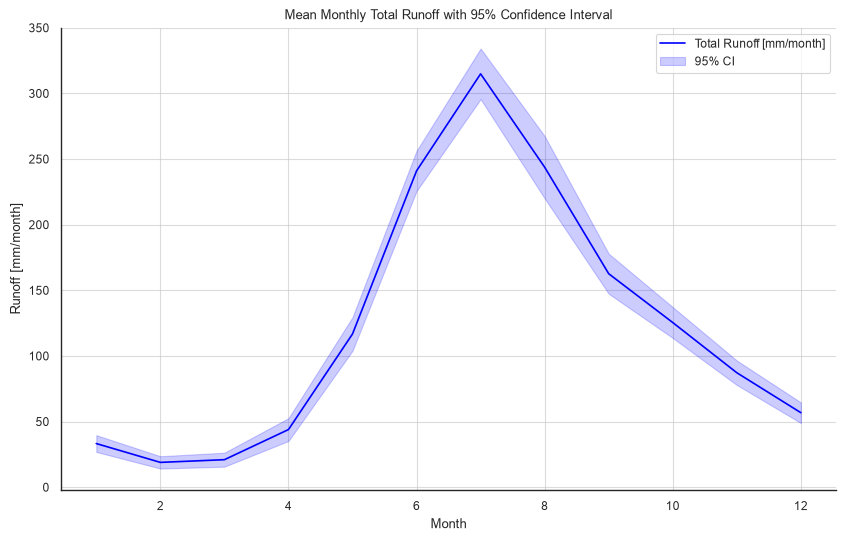

In [41]:
monthly_mean, ci = group_by_month_with_ci(multiple_results)

plot_monthly_runoff_with_ci(monthly_mean, ci)

monthly_mean

# TODO: remove simulation column

## (Week 2) Assessing the changes to streamflow in a future climate
### Generate a future climate ensemble consisting of n multiple realizations (simulations) for 5 climate trajectories (climate models) and 2 different greenhouse gas (GHG) emission scenarios applying the delta-change approach.

In [42]:
generate_future_climate(
    data=simulated_data,
    name="exp_first",
    output_folder=future_dir,
)

Generating future climate data. Be patient...
Future climate data for CLMCOM-CCLM4-ECEARTH RCP4.5 saved to C:\Users\noboe\polybox\26A_WatershedModeling\Exercises_3\climate-impacts\data\FutureGsteig_O2_D2\exp_first_CLMCOM-CCLM4-ECEARTH_RCP4.5.csv
Future climate data for CLMCOM-CCLM4-ECEARTH RCP8.5 saved to C:\Users\noboe\polybox\26A_WatershedModeling\Exercises_3\climate-impacts\data\FutureGsteig_O2_D2\exp_first_CLMCOM-CCLM4-ECEARTH_RCP8.5.csv
Future climate data for CLMCOM-CCLM4-HADGEM RCP4.5 saved to C:\Users\noboe\polybox\26A_WatershedModeling\Exercises_3\climate-impacts\data\FutureGsteig_O2_D2\exp_first_CLMCOM-CCLM4-HADGEM_RCP4.5.csv
Future climate data for CLMCOM-CCLM4-HADGEM RCP8.5 saved to C:\Users\noboe\polybox\26A_WatershedModeling\Exercises_3\climate-impacts\data\FutureGsteig_O2_D2\exp_first_CLMCOM-CCLM4-HADGEM_RCP8.5.csv
Future climate data for DMI-HIRHAM-ECEARTH RCP4.5 saved to C:\Users\noboe\polybox\26A_WatershedModeling\Exercises_3\climate-impacts\data\FutureGsteig_O2_D2\ex

### Simulate future streamflow using the future climate ensemble and the Bucket

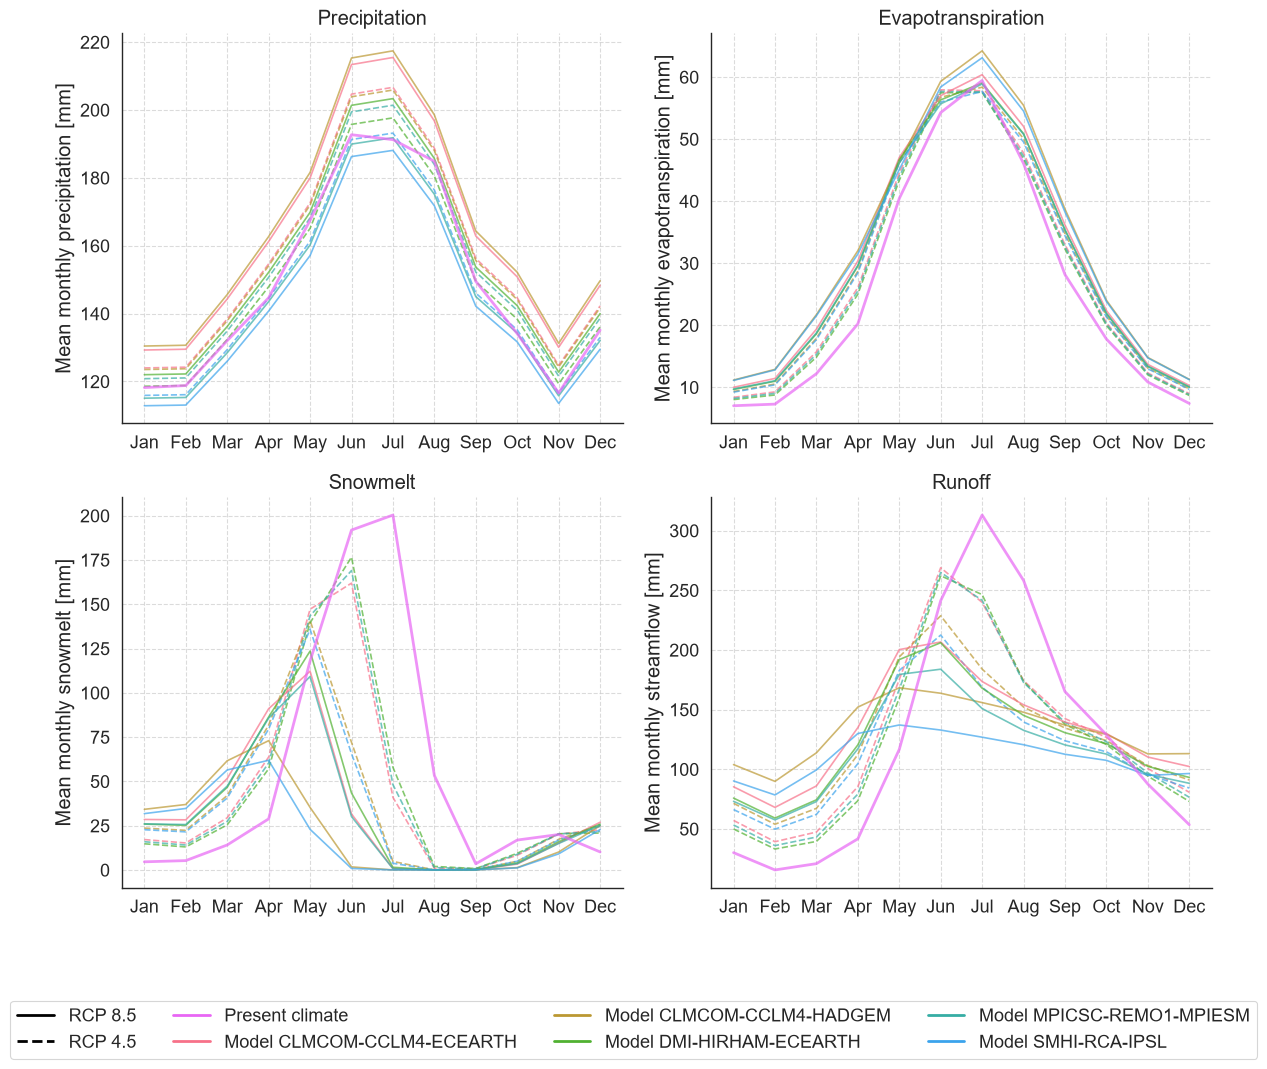

In [43]:
future_data_folder = future_dir
results = run_model_for_future_climate(
    future_data_folder=future_data_folder,
    bucket_model=bucket_model,
)

# Prepare present data for plotting
present_monthly_mean, _ = group_by_month_with_ci(present_results)
present_monthly_mean['total_runoff'] = present_monthly_mean['Q_s'] + present_monthly_mean['Q_gw']

plot_climate_scenarios(
    results,
    present_results=present_monthly_mean,
) # Again, you can add the output_destination parameter to save the plot

### Simulate future streamflow using the future climate ensemble and the Bucket Model

In [ ]:
folder_path = future_dir # Path to the folder containing the future climate scenarios
combined_df = simulate_and_aggregate_streamflows(folder_path, bucket_model, 50)

In [ ]:
combined_df

,Simulation,Streamflow,Climate_Model,Scenario
0,1,1524.968332,CLMCOM_CCLM4_ECEARTH,RCP4.5
1,2,1527.794623,CLMCOM_CCLM4_ECEARTH,RCP4.5
2,3,1540.676585,CLMCOM_CCLM4_ECEARTH,RCP4.5
3,4,1544.070756,CLMCOM_CCLM4_ECEARTH,RCP4.5
4,5,1535.223859,CLMCOM_CCLM4_ECEARTH,RCP4.5
...,...,...,...,...
495,46,1318.323181,SMHI_RCA_IPSL,RCP8.5
496,47,1341.799998,SMHI_RCA_IPSL,RCP8.5
497,48,1266.866386,SMHI_RCA_IPSL,RCP8.5
498,49,1292.884227,SMHI_RCA_IPSL,RCP8.5


### Partition the hydrological (streamflow) uncertainties predicted in a future climate into their climatic sources – emission uncertainty, climate model uncertainty, and stochastic uncertainty

In [ ]:
uncertainty = UncertaintyAnalysis(combined_df)

tu = uncertainty.calculate_tu('Streamflow')
eu, eu_partition = uncertainty.calculate_eu('Streamflow', tu)
cmu, cmu_partition = uncertainty.calculate_cmu('Streamflow', tu)
su, su_partition = uncertainty.calculate_su('Streamflow', tu)

print(f"Total Uncertainty: {tu}")
print(f"Emission Scenario Uncertainty: {eu} (Partition: {eu_partition})")
print(f"Climate Model Uncertainty: {cmu} (Partition: {cmu_partition})")
print(f"Stochastic Uncertainty: {su} (Partition: {su_partition})")

Total Uncertainty: 285.05
Emission Scenario Uncertainty: 0.93 (Partition: 0.0)
Climate Model Uncertainty: 198.91 (Partition: 0.7)
Stochastic Uncertainty: 97.11 (Partition: 0.34)
